# Order Delivery Time Prediction

## Objectives
The objective of this assignment is to build a regression model that predicts the delivery time for orders placed through Porter. The model will use various features such as the items ordered, the restaurant location, the order protocol, and the availability of delivery partners.

The key goals are:
- Predict the delivery time for an order based on multiple input features
- Improve delivery time predictions to optimiae operational efficiency
- Understand the key factors influencing delivery time to enhance the model's accuracy

## Data Pipeline
The data pipeline for this assignment will involve the following steps:
1. **Data Loading**
2. **Data Preprocessing and Feature Engineering**
3. **Exploratory Data Analysis**
4. **Model Building**
5. **Model Inference**

## Data Understanding
The dataset contains information on orders placed through Porter, with the following columns:

| Field                     | Description                                                                                 |
|---------------------------|---------------------------------------------------------------------------------------------|
| market_id                 | Integer ID representing the market where the restaurant is located.                         |
| created_at                | Timestamp when the order was placed.                                                        |
| actual_delivery_time      | Timestamp when the order was delivered.                                                     |
| store_primary_category    | Category of the restaurant (e.g., fast food, dine-in).                                      |
| order_protocol            | Integer representing how the order was placed (e.g., via Porter, call to restaurant, etc.). |
| total_items               | Total number of items in the order.                                                         |
| subtotal                  | Final price of the order.                                                                   |
| num_distinct_items        | Number of distinct items in the order.                                                      |
| min_item_price            | Price of the cheapest item in the order.                                                    |
| max_item_price            | Price of the most expensive item in the order.                                              |
| total_onshift_dashers     | Number of delivery partners on duty when the order was placed.                              |
| total_busy_dashers        | Number of delivery partners already occupied with other orders.                             |
| total_outstanding_orders  | Number of orders pending fulfillment at the time of the order.                              |
| distance                  | Total distance from the restaurant to the customer.                                         |


## **Importing Necessary Libraries**

In [2]:
# Import essential libraries for data manipulation and analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

import statsmodels.api as sm


In [3]:
## **1. Loading the data**
##Load 'porter_data_1.csv' as a DataFrame

In [4]:
# Importing the file porter_data_1.csv
df=pd.read_csv("porter_data_1.csv")
print(df)





        market_id           created_at actual_delivery_time  \
0             1.0  2015-02-06 22:24:17  2015-02-06 23:11:17   
1             2.0  2015-02-10 21:49:25  2015-02-10 22:33:25   
2             2.0  2015-02-16 00:11:35  2015-02-16 01:06:35   
3             1.0  2015-02-12 03:36:46  2015-02-12 04:35:46   
4             1.0  2015-01-27 02:12:36  2015-01-27 02:58:36   
...           ...                  ...                  ...   
175772        1.0  2015-02-17 00:19:41  2015-02-17 01:02:41   
175773        1.0  2015-02-13 00:01:59  2015-02-13 01:03:59   
175774        1.0  2015-01-24 04:46:08  2015-01-24 05:32:08   
175775        1.0  2015-02-01 18:18:15  2015-02-01 19:03:15   
175776        1.0  2015-02-08 19:24:33  2015-02-08 20:01:33   

        store_primary_category  order_protocol  total_items  subtotal  \
0                            4             1.0            4      3441   
1                           46             2.0            1      1900   
2                       

## **2. Data Preprocessing and Feature Engineering** <font color = red>[15 marks]</font> <br>

#### **2.1 Fixing the Datatypes**  <font color = red>[5 marks]</font> <br>
The current timestamps are in object format and need conversion to datetime format for easier handling and intended functionality

##### **2.1.1** <font color = red>[2 marks]</font> <br>
Convert date and time fields to appropriate data type

In [5]:
# Convert 'created_at' and 'actual_delivery_time' columns to datetime format
df['created_at'] = pd.to_datetime(df['created_at'])
df['actual_delivery_time'] = pd.to_datetime(df['actual_delivery_time'])





##### **2.1.2**  <font color = red>[3 marks]</font> <br>
Convert categorical fields to appropriate data type

In [6]:
#Convert categorical features to category type
df.info()








<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 14 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   market_id                 175777 non-null  float64       
 1   created_at                175777 non-null  datetime64[ns]
 2   actual_delivery_time      175777 non-null  datetime64[ns]
 3   store_primary_category    175777 non-null  int64         
 4   order_protocol            175777 non-null  float64       
 5   total_items               175777 non-null  int64         
 6   subtotal                  175777 non-null  int64         
 7   num_distinct_items        175777 non-null  int64         
 8   min_item_price            175777 non-null  int64         
 9   max_item_price            175777 non-null  int64         
 10  total_onshift_dashers     175777 non-null  float64       
 11  total_busy_dashers        175777 non-null  float64       
 12  to

#### **2.2 Feature Engineering** <font color = red>[5 marks]</font> <br>
Calculate the time taken to execute the delivery as well as extract the hour and day at which the order was placed

##### **2.2.1** <font color = red>[2 marks]</font> <br>
Calculate the time taken using the features `actual_delivery_time` and `created_at`

In [7]:
# Calculate time taken in minutes
df.info()
df['time_taken_minutes'] = (
    df['actual_delivery_time'] - df['created_at']
).dt.total_seconds() / 60









<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 14 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   market_id                 175777 non-null  float64       
 1   created_at                175777 non-null  datetime64[ns]
 2   actual_delivery_time      175777 non-null  datetime64[ns]
 3   store_primary_category    175777 non-null  int64         
 4   order_protocol            175777 non-null  float64       
 5   total_items               175777 non-null  int64         
 6   subtotal                  175777 non-null  int64         
 7   num_distinct_items        175777 non-null  int64         
 8   min_item_price            175777 non-null  int64         
 9   max_item_price            175777 non-null  int64         
 10  total_onshift_dashers     175777 non-null  float64       
 11  total_busy_dashers        175777 non-null  float64       
 12  to

##### **2.2.2** <font color = red>[3 marks]</font> <br>
Extract the hour at which the order was placed and which day of the week it was. Drop the unnecessary columns.

In [8]:
# Extract the hour and day of week from the 'created_at' timestamp
df['created_hour'] = df['created_at'].dt.hour
df['created_dayofweek'] = df['created_at'].dt.dayofweek
df['isWeekend'] = df['created_dayofweek'].isin([5, 6]).astype(int)
df



# Create a categorical feature 'isWeekend'



,market_id,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,distance,time_taken_minutes,created_hour,created_dayofweek,isWeekend
0,1.0,2015-02-06 22:24:17,2015-02-06 23:11:17,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,34.44,47.0,22,4,0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:33:25,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,27.60,44.0,21,1,0
2,2.0,2015-02-16 00:11:35,2015-02-16 01:06:35,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,11.56,55.0,0,0,0
3,1.0,2015-02-12 03:36:46,2015-02-12 04:35:46,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,31.80,59.0,3,3,0
4,1.0,2015-01-27 02:12:36,2015-01-27 02:58:36,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,8.20,46.0,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175772,1.0,2015-02-17 00:19:41,2015-02-17 01:02:41,28,4.0,3,1389,3,345,649,17.0,17.0,23.0,13.24,43.0,0,1,0
175773,1.0,2015-02-13 00:01:59,2015-02-13 01:03:59,28,4.0,6,3010,4,405,825,12.0,11.0,14.0,36.60,62.0,0,4,0
175774,1.0,2015-01-24 04:46:08,2015-01-24 05:32:08,28,4.0,5,1836,3,300,399,39.0,41.0,40.0,31.80,46.0,4,5,1
175775,1.0,2015-02-01 18:18:15,2015-02-01 19:03:15,58,1.0,1,1175,1,535,535,7.0,7.0,12.0,15.36,45.0,18,6,1


In [9]:
# Drop unnecessary columns
df.drop(["created_at"],axis=1,inplace=True)
df.drop(["actual_delivery_time"],axis=1,inplace=True)
df



,market_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,distance,time_taken_minutes,created_hour,created_dayofweek,isWeekend
0,1.0,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,34.44,47.0,22,4,0
1,2.0,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,27.60,44.0,21,1,0
2,2.0,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,11.56,55.0,0,0,0
3,1.0,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,31.80,59.0,3,3,0
4,1.0,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,8.20,46.0,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175772,1.0,28,4.0,3,1389,3,345,649,17.0,17.0,23.0,13.24,43.0,0,1,0
175773,1.0,28,4.0,6,3010,4,405,825,12.0,11.0,14.0,36.60,62.0,0,4,0
175774,1.0,28,4.0,5,1836,3,300,399,39.0,41.0,40.0,31.80,46.0,4,5,1
175775,1.0,58,1.0,1,1175,1,535,535,7.0,7.0,12.0,15.36,45.0,18,6,1


#### **2.3 Creating training and validation sets** <font color = red>[5 marks]</font> <br>

##### **2.3.1** <font color = red>[2 marks]</font> <br>
 Define target and input features

In [10]:
# Define target variable (y) and features (X)
X=df.drop(["time_taken_minutes"],axis=1)
y=df["time_taken_minutes"]
y


0         47.0
1         44.0
2         55.0
3         59.0
4         46.0
          ... 
175772    43.0
175773    62.0
175774    46.0
175775    45.0
175776    37.0
Name: time_taken_minutes, Length: 175777, dtype: float64

##### **2.3.2** <font color = red>[3 marks]</font> <br>
 Split the data into training and test sets

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)




## **3. Exploratory Data Analysis on Training Data** <font color = red>[20 marks]</font> <br>
1. Analyzing the correlation between variables to identify patterns and relationships
2. Identifying and addressing outliers to ensure the integrity of the analysis
3. Exploring the relationships between variables and examining the distribution of the data for better insights

#### **3.1 Feature Distributions** <font color = red> [7 marks]</font> <br>


In [12]:
# Define numerical and categorical columns for easy EDA and data manipulation
X.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 15 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   market_id                 175777 non-null  float64
 1   store_primary_category    175777 non-null  int64  
 2   order_protocol            175777 non-null  float64
 3   total_items               175777 non-null  int64  
 4   subtotal                  175777 non-null  int64  
 5   num_distinct_items        175777 non-null  int64  
 6   min_item_price            175777 non-null  int64  
 7   max_item_price            175777 non-null  int64  
 8   total_onshift_dashers     175777 non-null  float64
 9   total_busy_dashers        175777 non-null  float64
 10  total_outstanding_orders  175777 non-null  float64
 11  distance                  175777 non-null  float64
 12  created_hour              175777 non-null  int32  
 13  created_dayofweek         175777 non-null  i

##### **3.1.1** <font color = red>[3 marks]</font> <br>
Plot distributions for numerical columns in the training set to understand their spread and any skewness

In [13]:
# Plot distributions for all numerical columns
X


,market_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,distance,created_hour,created_dayofweek,isWeekend
0,1.0,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,34.44,22,4,0
1,2.0,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,27.60,21,1,0
2,2.0,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,11.56,0,0,0
3,1.0,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,31.80,3,3,0
4,1.0,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,8.20,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175772,1.0,28,4.0,3,1389,3,345,649,17.0,17.0,23.0,13.24,0,1,0
175773,1.0,28,4.0,6,3010,4,405,825,12.0,11.0,14.0,36.60,0,4,0
175774,1.0,28,4.0,5,1836,3,300,399,39.0,41.0,40.0,31.80,4,5,1
175775,1.0,58,1.0,1,1175,1,535,535,7.0,7.0,12.0,15.36,18,6,1


##### **3.1.2** <font color = red>[2 marks]</font> <br>
Check the distribution of categorical features

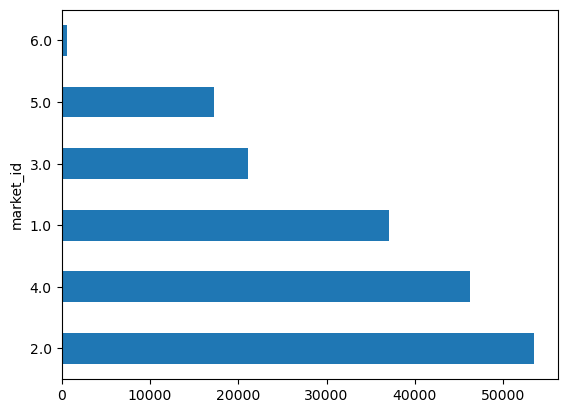

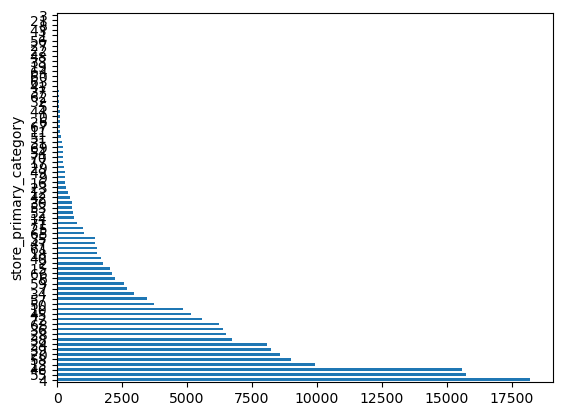

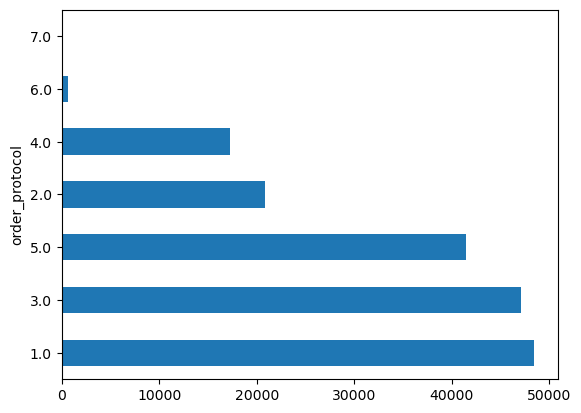

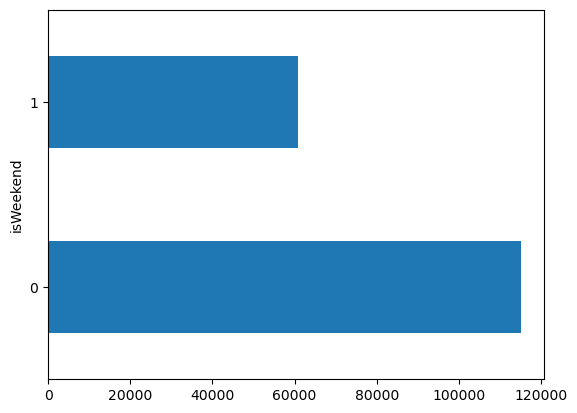

In [14]:
# Distribution of categorical columns
X['market_id'].value_counts().plot(kind='barh')
plt.show()
X["store_primary_category"].value_counts().plot(kind="barh")
plt.show()
X['order_protocol'].value_counts().plot(kind='barh')
plt.show()
X['isWeekend'].value_counts().plot(kind='barh')
plt.show()




##### **3.1.3** <font color = red>[2 mark]</font> <br>
Visualise the distribution of the target variable to understand its spread and any skewness

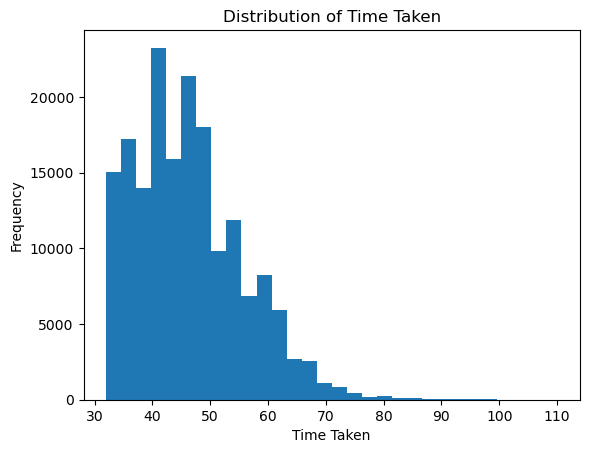

np.float64(0.7621906257372622)

In [15]:
# Distribution of time_taken
import matplotlib.pyplot as plt

plt.hist(df['time_taken_minutes'], bins=30)
plt.xlabel('Time Taken')
plt.ylabel('Frequency')
plt.title('Distribution of Time Taken')
plt.show()
df["time_taken_minutes"].skew()





#### **3.2 Relationships Between Features** <font color = red>[3 marks]</font> <br>

##### **3.2.1** <font color = red>[3 marks]</font> <br>
Scatter plots for important numerical and categorical features to observe how they relate to `time_taken`

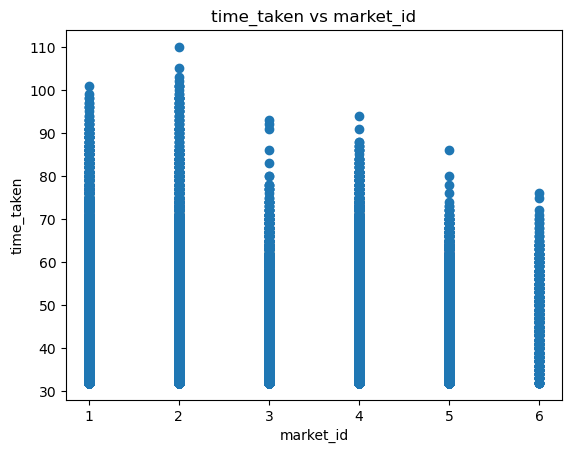

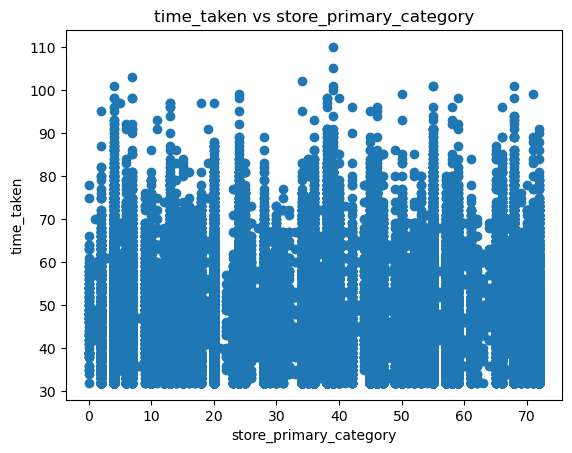

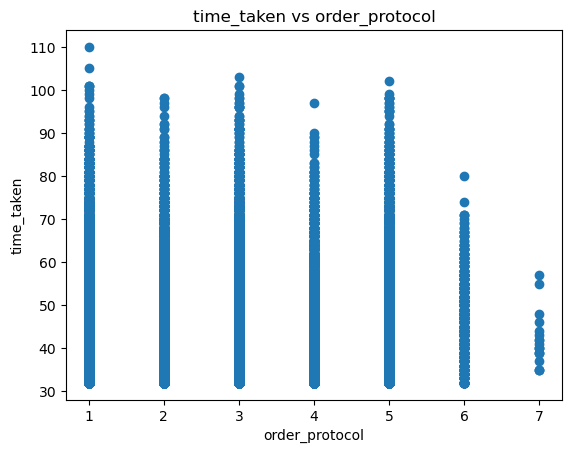

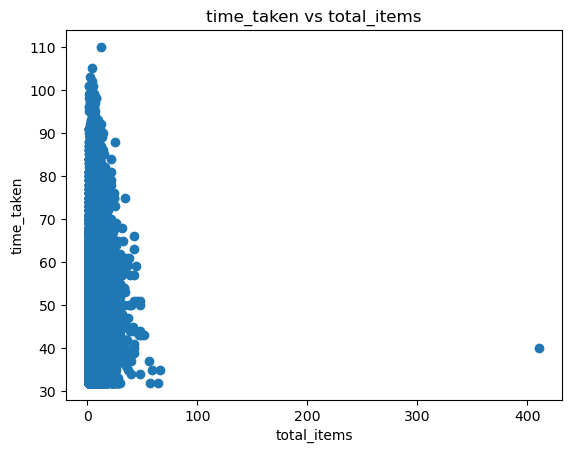

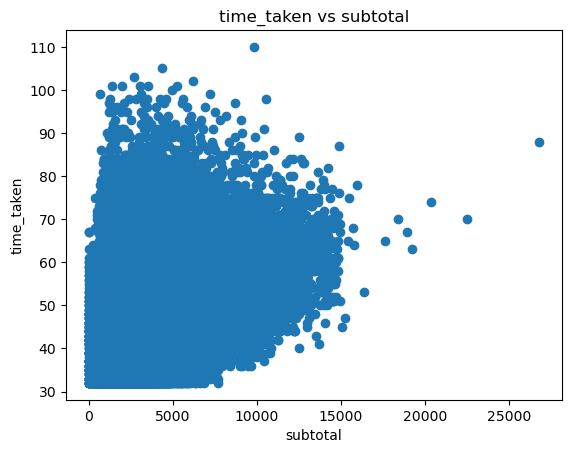

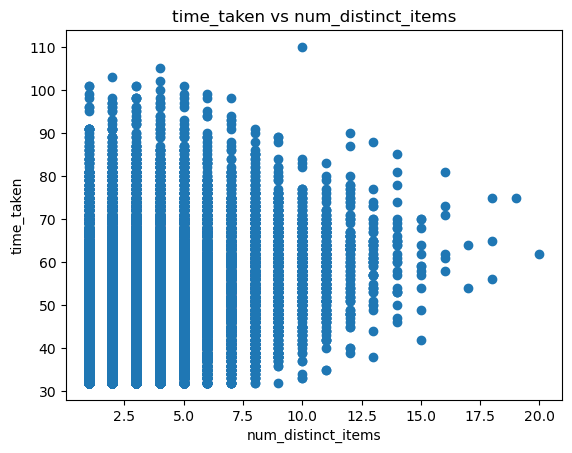

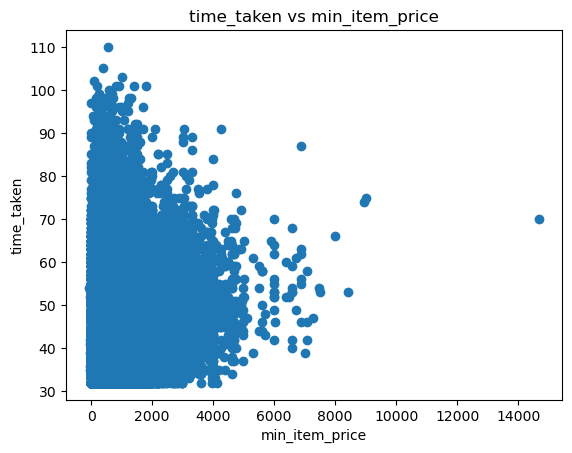

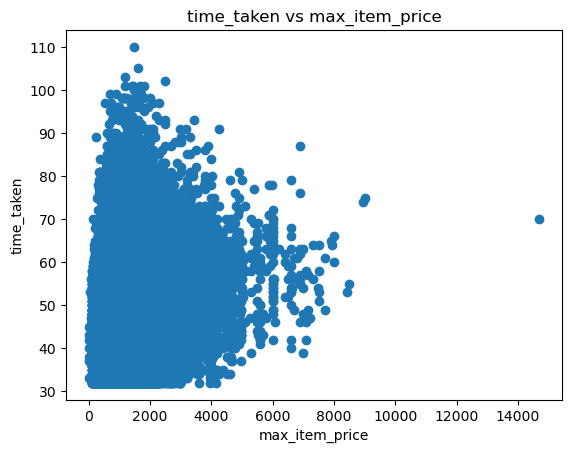

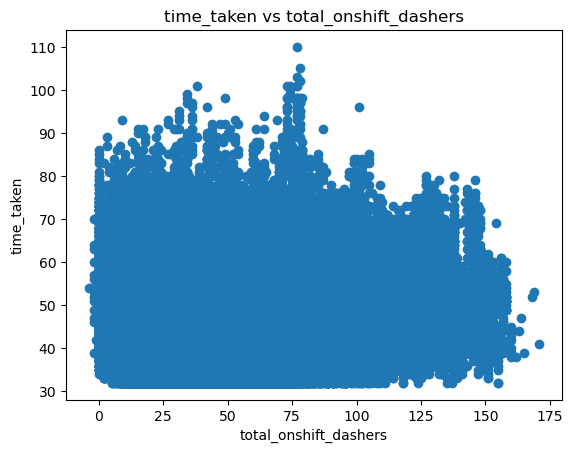

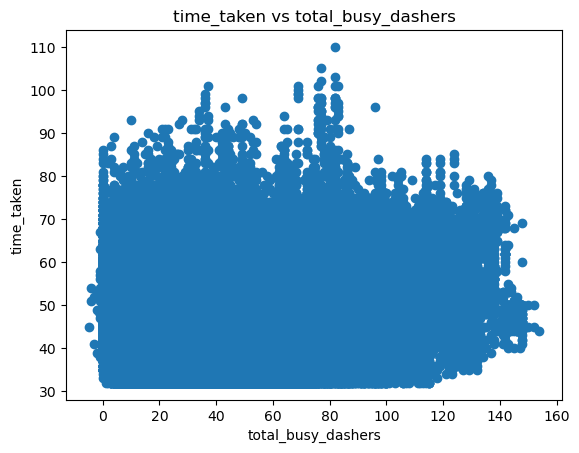

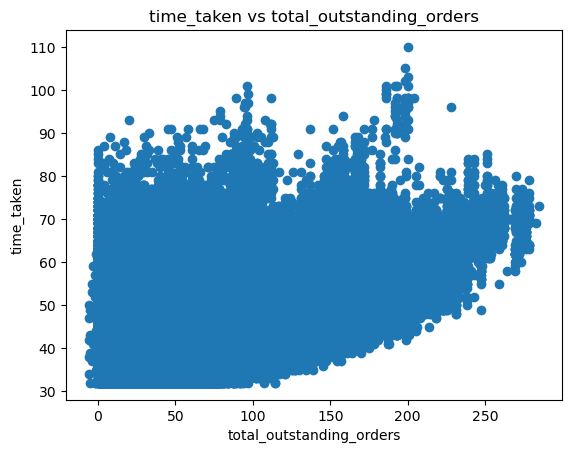

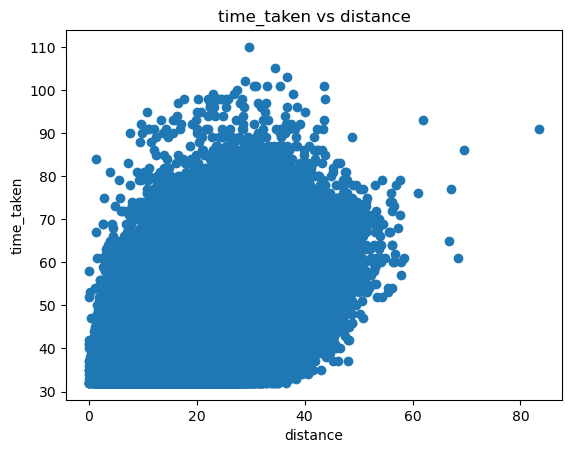

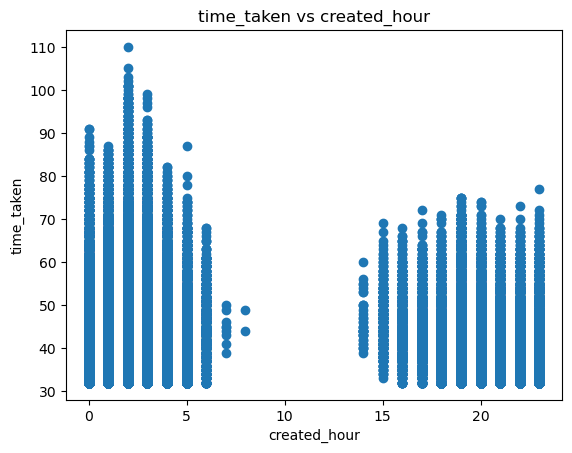

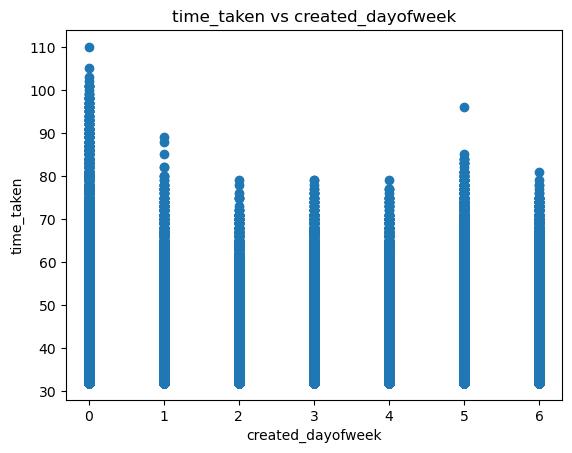

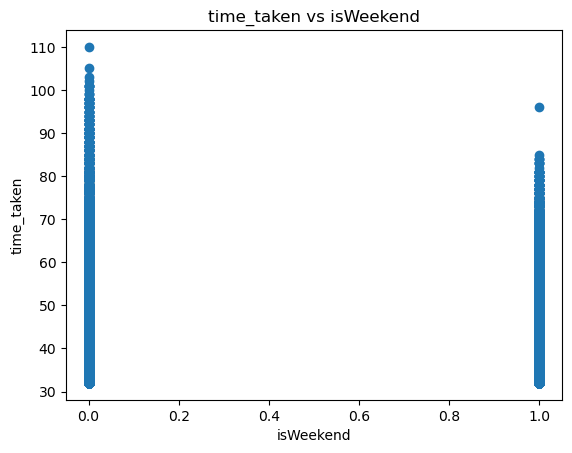

In [16]:
# Scatter plot to visualise the relationship between time_taken and other features

for col in X:
    plt.figure()
    plt.scatter(df[col], df['time_taken_minutes'])
    plt.xlabel(col)
    plt.ylabel('time_taken')
    plt.title(f'time_taken vs {col}')
    plt.show()





<Figure size 1200x1200 with 0 Axes>

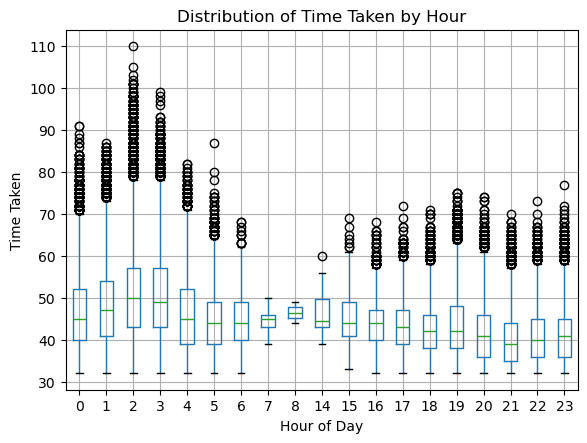

In [17]:
# import matplotlib.pyplot as plt

plt.figure(figsize=(12, 12))
df.boxplot(column='time_taken_minutes', by='created_hour')
plt.xlabel('Hour of Day')
plt.ylabel('Time Taken')
plt.title('Distribution of Time Taken by Hour')
plt.suptitle('')  # removes default pandas title
plt.show()




#### **3.3 Correlation Analysis** <font color = red>[5 marks]</font> <br>
Check correlations between numerical features to identify which variables are strongly related to `time_taken`

##### **3.3.1** <font color = red>[3 marks]</font> <br>
Plot a heatmap to display correlations

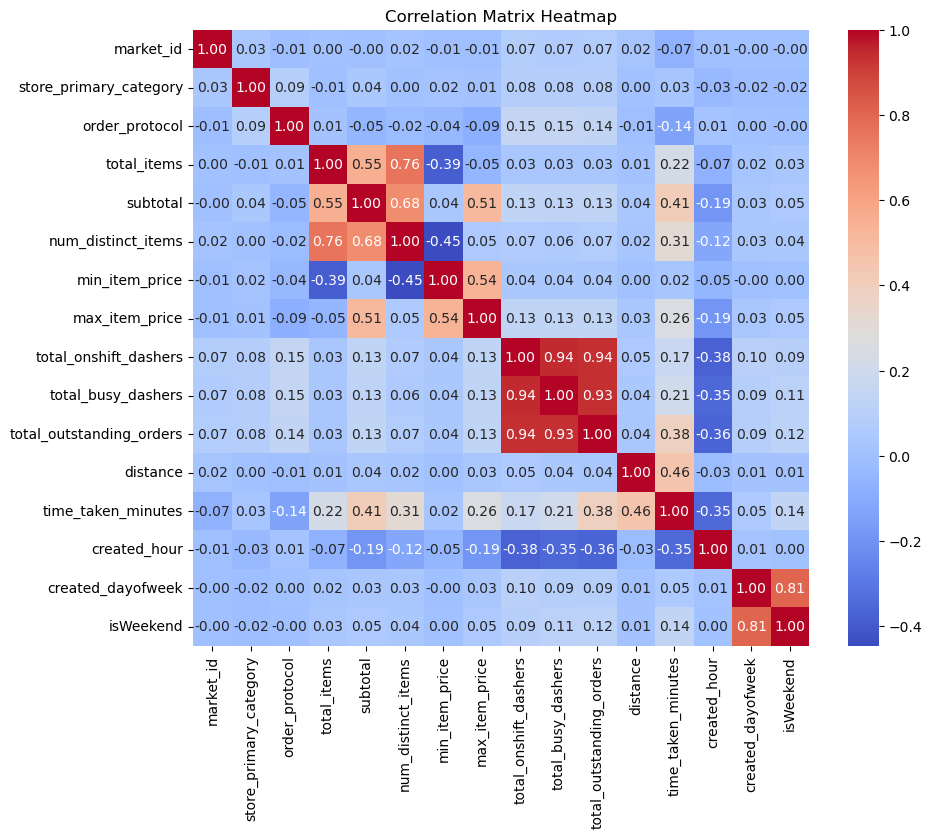

In [18]:
# Plot the heatmap of the correlation matrix
corr = df.corr()


plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True
)
plt.title("Correlation Matrix Heatmap")
plt.show()




##### **3.3.2** <font color = red>[2 marks]</font> <br>
Drop the columns with weak correlations with the target variable

In [19]:
# Drop 3-5 weakly correlated columns from training dataset
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

model = LinearRegression()
rfe = RFE(estimator=model, n_features_to_select=5)

rfe.fit(X_train, y_train)
selected_features = X_train.columns[rfe.support_]
print(selected_features)
X_test=X_test[selected_features]
X_test
X_train=X_train[selected_features]
X_train





Index(['market_id', 'order_protocol', 'num_distinct_items', 'distance',
       'isWeekend'],
      dtype='object')


,market_id,order_protocol,num_distinct_items,distance,isWeekend
102712,2.0,2.0,1,30.32,0
94576,4.0,3.0,1,31.16,0
49784,1.0,3.0,4,18.16,0
37753,3.0,1.0,2,33.44,0
91728,2.0,1.0,1,31.56,0
...,...,...,...,...,...
119879,2.0,5.0,1,37.04,1
103694,2.0,1.0,3,27.72,0
131932,6.0,5.0,2,21.92,0
146867,5.0,2.0,4,23.60,1


#### **3.4 Handling the Outliers** <font color = red>[5 marks]</font> <br>



##### **3.4.1** <font color = red>[2 marks]</font> <br>
Visualise potential outliers for the target variable and other numerical features using boxplots

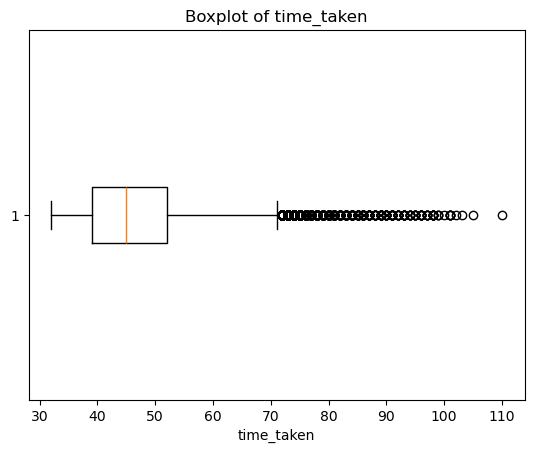

In [20]:
# Boxplot for time_taken
import matplotlib.pyplot as plt

plt.figure()
plt.boxplot(df['time_taken_minutes'], vert=False)
plt.xlabel('time_taken')
plt.title('Boxplot of time_taken')
plt.show()






##### **3.4.2** <font color = red>[3 marks]</font> <br>
Handle outliers present in all columns

In [21]:
# Handle outliers
Q1 = df["distance"].quantile(0.25)
Q3 = df["distance"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

X_train["distance"] = X_train["distance"].clip(lower, upper)




## **4. Exploratory Data Analysis on Validation Data** <font color = red>[optional]</font> <br>
Optionally, perform EDA on test data to see if the distribution match with the training data

In [22]:
# Define numerical and categorical columns for easy EDA and data manipulation



#### **4.1 Feature Distributions**


##### **4.1.1**
Plot distributions for numerical columns in the validation set to understand their spread and any skewness

In [23]:
# Plot distributions for all numerical columns



##### **4.1.2**
Check the distribution of categorical features

In [24]:
# Distribution of categorical columns



##### **4.1.3**
Visualise the distribution of the target variable to understand its spread and any skewness

In [25]:
# Distribution of time_taken



#### **4.2 Relationships Between Features**
Scatter plots for numerical features to observe how they relate to each other, especially to `time_taken`

In [26]:
# Scatter plot to visualise the relationship between time_taken and other features



#### **4.3** Drop the columns with weak correlations with the target variable

In [27]:
# Drop the weakly correlated columns from training dataset



## **5. Model Building** <font color = red>[15 marks]</font> <br>

#### **Import Necessary Libraries**

In [28]:
# Import libraries




#### **5.1 Feature Scaling** <font color = red>[3 marks]</font> <br>

In [29]:
# Apply scaling to the numerical columns
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)





Note that linear regression is agnostic to feature scaling. However, with feature scaling, we get the coefficients to be somewhat on the same scale so that it becomes easier to compare them.

#### **5.2 Build a linear regression model** <font color = red>[5 marks]</font> <br>

You can choose from the libraries *statsmodels* and *scikit-learn* to build the model.

In [31]:
# Train the model using the training data
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)


In [32]:
# Make predictions


In [33]:
# Find results for evaluation metrics

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Train metrics
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

# Test metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print("Train MAE:", train_mae)
print("Train RMSE:", train_rmse)
print("Train R2:", train_r2)

print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)
print("Test R2:", test_r2)
test_r2


Train MAE: 5.64987981247978
Train RMSE: 7.455626420484888
Train R2: 0.3601090052162005
Test MAE: 5.6909070791131136
Test RMSE: 7.526097876533554
Test R2: 0.3528629404568402


0.3528629404568402

Note that we have 12 (depending on how you select features) training features. However, not all of them would be useful. Let's say we want to take the most relevant 8 features.

We will use Recursive Feature Elimination (RFE) here.

For this, you can look at the coefficients / p-values of features from the model summary and perform feature elimination, or you can use the RFE module provided with *scikit-learn*.

#### **5.3 Build the model and fit RFE to select the most important features** <font color = red>[7 marks]</font> <br>

For RFE, we will start with all features and use
the RFE method to recursively reduce the number of features one-by-one.

After analysing the results of these iterations, we select the one that has a good balance between performance and number of features.

In [34]:
# Loop through the number of features and test the model
selected_features


Index(['market_id', 'order_protocol', 'num_distinct_items', 'distance',
       'isWeekend'],
      dtype='object')

In [35]:
# Build the final model with selected number of features



## **6. Results and Inference** <font color = red>[5 marks]</font> <br>

#### **6.1 Perform Residual Analysis** <font color = red>[3 marks]</font> <br>

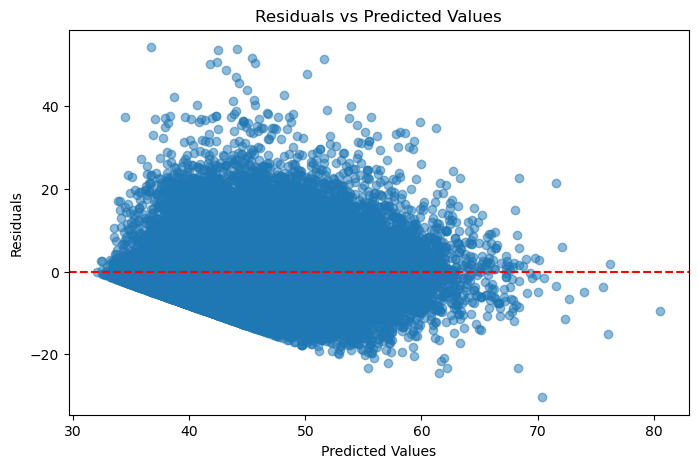

(140621, 20)

In [39]:
# Perform residual analysis using plots like residuals vs predicted values, Q-Q plot and residual histogram
# Assume y_test and y_test_pred exist
residuals = y_test - y_test_pred
plt.figure(figsize=(8,5))
plt.scatter(y_test_pred, residuals, alpha=0.5)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.show()
X_train.shape




[Your inferences here:]



#### **6.2 Perform Coefficient Analysis** <font color = red>[2 marks]</font> <br>

Perform coefficient analysis to find how changes in features affect the target.
Also, the features were scaled, so interpret the scaled and unscaled coefficients to understand the impact of feature changes on delivery time.


Additionally, we can analyse the effect of a unit change in a feature. In other words, because we have scaled the features, a unit change in the features will not translate directly to the model. Use scaled and unscaled coefficients to find how will a unit change in a feature affect the target.

In [ ]:
# Analyze the effect of a unit change in a feature, say 'total_items'



Note:
The coefficients on the original scale might differ greatly in magnitude from the scaled coefficients, but they both describe the same relationships between variables.

Interpretation is key: Focus on the direction and magnitude of the coefficients on the original scale to understand the impact of each variable on the response variable in the original units.

Include conclusions in your report document.

## Subjective Questions <font color = red>[20 marks]</font>

Answer the following questions only in the notebook. Include the visualisations/methodologies/insights/outcomes from all the above steps in your report.

#### Subjective Questions based on Assignment

##### **Question 1.** <font color = red>[2 marks]</font> <br>

Are there any categorical variables in the data? From your analysis of the categorical variables from the dataset, what could you infer about their effect on the dependent variable?

**Answer:**
>

Protocol:

Some protocols may have consistently longer delivery times due to system or process constraints

Order type:

“Priority” orders may have lower average delivery time, “normal” higher

Traffic / hour groups:

Delivery times could increase during peak hours

Night hours → lower delivery time

Categorical effect:

Categories with higher median values → tend to increase the dependent variable

Categories with lower median values → tend to decrease it

---



##### **Question 2.** <font color = red>[1 marks]</font> <br>
What does `test_size = 0.2` refer to during splitting the data into training and test sets?

**Answer:**
>

it refers to split the data in to 80 percent train data and 20 percent test data


---



##### **Question 3.** <font color = red>[1 marks]</font> <br>
Looking at the heatmap, which one has the highest correlation with the target variable?  

**Answer:**
>

distance

---



##### **Question 4.** <font color = red>[2 marks]</font> <br>
What was your approach to detect the outliers? How did you address them?

**Answer:**

>

iqr capping, because it will do remove or delete the data

---



##### **Question 5.** <font color = red>[2 marks]</font> <br>
Based on the final model, which are the top 3 features significantly affecting the delivery time?

**Answer:**
>

distance,hour,order_protocol

---



#### General Subjective Questions

##### **Question 6.** <font color = red>[3 marks]</font> <br>
Explain the linear regression algorithm in detail

**Answer:**
>


it uses the linear line to get best fit and predicts the data from the input in a more genralized way.The co relation between the
input and ouput features should be strong to initiate linear regression.

---



##### **Question 7.** <font color = red>[2 marks]</font> <br>
Explain the difference between simple linear regression and multiple linear regression

**Answer:**
>

it has single input features on the other hand multiple linear reg has multiple input features

---



##### **Question 8.** <font color = red>[2 marks]</font> <br>
What is the role of the cost function in linear regression, and how is it minimized?

**Answer:**
>


it is used to find the cummulative error of the prediction,and it helps in building the gradient curve,based on that curve only 
the linear reg produces the best fit line

---



##### **Question 9.** <font color = red>[2 marks]</font> <br>
Explain the difference between overfitting and underfitting.



**Answer:**

>

overfitting-low bias high variance, underfitting- high bias high variance

---



##### **Question 10.** <font color = red>[3 marks]</font> <br>
How do residual plots help in diagnosing a linear regression model?

**Answer:**
>

In [ ]:
it helps the find the assumption that if the residual plot has no pattern in the distribution of the data means, the model is working well.

## Improved RFE Selection

The assignment expects comparing multiple feature counts using RFE.
Use the following code in place of a fixed `n_features_to_select=5`.

```python
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

scores = []

for n in range(1, X_train_scaled.shape[1] + 1):
    rfe = RFE(LinearRegression(), n_features_to_select=n)
    Xtr = rfe.fit_transform(X_train_scaled, y_train)
    Xte = rfe.transform(X_test_scaled)

    model = LinearRegression()
    model.fit(Xtr, y_train)

    pred = model.predict(Xte)
    scores.append((n, r2_score(y_test, pred)))

best_n = max(scores, key=lambda x: x[1])[0]

rfe = RFE(LinearRegression(), n_features_to_select=best_n)
X_train_rfe = rfe.fit_transform(X_train_scaled, y_train)
X_test_rfe = rfe.transform(X_test_scaled)

selected_features = X.columns[rfe.get_support()]
print(selected_features)
```


In [ ]:
# QQ Plot for residual normality
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Assumes `model` is a statsmodels OLS result or `residuals` already exists.
try:
    residuals = model.resid
except Exception:
    try:
        residuals = y_test - y_pred
    except Exception:
        residuals = residuals

sm.qqplot(residuals, line='45')
plt.title("Q-Q Plot of Residuals")
plt.show()


In [ ]:
# Improved RFE comparison (recommended by assignment)
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

scores=[]
for n in range(1, X_train_scaled.shape[1]+1):
    selector=RFE(LinearRegression(), n_features_to_select=n)
    Xtr=selector.fit_transform(X_train_scaled,y_train)
    Xte=selector.transform(X_test_scaled)
    m=LinearRegression().fit(Xtr,y_train)
    scores.append((n,r2_score(y_test,m.predict(Xte))))

best_n=max(scores,key=lambda x:x[1])[0]
print("Best number of features:",best_n)
